## 1. Dataset Loading, Cleaning & Chronological Split
- Loads the PJM energy consumption dataset (`energy_consumption.csv`).
- Validates schema (`Datetime`, `AEP_MW`), standardizes column names, and sets a datetime index.
- Handles missing values and removes duplicate timestamps (DST transitions).
- Performs a strict 3-way chronological split: 70% Train, 15% Validation, 15% Test.
- Fits `MinMaxScaler` strictly on the training data to prevent data leakage.

In [12]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

file_path = "../data/energy_consumption.csv"
if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found at {file_path}.")

# 1. Load dataset
df = pd.read_csv(file_path)

# 2. Schema validation
expected_columns = ['Datetime', 'AEP_MW']
if not all(col in df.columns for col in expected_columns):
    raise ValueError(f"Schema validation failed! Expected columns: {expected_columns}")

# 3. Standardize column names and set datetime index
df = df.rename(columns={'Datetime': 'datetime', 'AEP_MW': 'consumption_mw'})
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)
df = df.sort_index()

# 4. Handle missing values and remove duplicate timestamps (DST transitions)
df = df.dropna()
df = df[~df.index.duplicated(keep='first')]

print(f"Clean and unique total records: {len(df)}")

# 5. 3-Way Chronological Split (70% Train, 15% Validation, 15% Test)
total_len = len(df)
train_end = int(total_len * 0.70)
val_end = int(total_len * 0.85)

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

print(f"Train set shape: {train_df.shape}")
print(f"Validation set shape: {val_df.shape}")
print(f"Test set shape: {test_df.shape}")

# 6. Fit MinMaxScaler strictly on training data to prevent data leakage
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_df[['consumption_mw']])
val_scaled = scaler.transform(val_df[['consumption_mw']])
test_scaled = scaler.transform(test_df[['consumption_mw']])

print("Data scaling completed successfully with zero data leakage.")

Clean and unique total records: 121269
Train set shape: (84888, 1)
Validation set shape: (18190, 1)
Test set shape: (18191, 1)
Data scaling completed successfully with zero data leakage.


## 2. Sequence Creation for Time Series Forecasting
- Defines a sliding window function with a lookback window of 24 hours.
- Formats scaled data into sequential input features (`X`) and target labels (`y`) for time-series modeling.

In [13]:
import numpy as np

def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:(i + seq_length)]
        y = data[i + seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

# Define lookback window (e.g., 24 hours of past data to predict the next hour)
seq_length = 24

X_train, y_train = create_sequences(train_scaled, seq_length)
X_val, y_val = create_sequences(val_scaled, seq_length)
X_test, y_test = create_sequences(test_scaled, seq_length)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape: {X_val.shape}, y_val shape: {y_val.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (84864, 24, 1), y_train shape: (84864, 1)
X_val shape: (18166, 24, 1), y_val shape: (18166, 1)
X_test shape: (18167, 24, 1), y_test shape: (18167, 1)


In [14]:
import torch
import torch.nn as nn

# Convert NumPy arrays to PyTorch Tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

# Define LSTM Architecture using PyTorch Module with correct parameter names
class EnergyLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_dim):
        super(EnergyLSTM, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2 if num_layers > 1 else 0.0
        )
        self.fc1 = nn.Linear(hidden_size, 25)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(25, output_dim)
        
    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        out = self.fc1(out)
        out = self.relu(out)
        out = self.fc2(out)
        return out

# Initialize model parameters
input_size = X_train.shape[2]
hidden_size = 50
num_layers = 1
output_dim = 1

model = EnergyLSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, output_dim=output_dim)

# Define Loss function and Optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

EnergyLSTM(
  (lstm): LSTM(1, 50, batch_first=True)
  (fc1): Linear(in_features=50, out_features=25, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=25, out_features=1, bias=True)
)


In [15]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Create TensorDatasets for batching
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Initialize DataLoaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Training Loop configuration
num_epochs = 10
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    model.train()
    epoch_train_loss = 0.0
    
    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        epoch_train_loss += loss.item() * batch_x.size(0)
        
    epoch_train_loss /= len(train_loader.dataset)
    
    # Validation phase
    model.eval()
    epoch_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            epoch_val_loss += loss.item() * batch_x.size(0)
            
    epoch_val_loss /= len(val_loader.dataset)
    
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {epoch_train_loss:.6f} | Val Loss: {epoch_val_loss:.6f}")

Epoch [1/10] | Train Loss: 0.003694 | Val Loss: 0.000383
Epoch [2/10] | Train Loss: 0.000355 | Val Loss: 0.000384
Epoch [3/10] | Train Loss: 0.000297 | Val Loss: 0.000245
Epoch [4/10] | Train Loss: 0.000278 | Val Loss: 0.000272
Epoch [5/10] | Train Loss: 0.000249 | Val Loss: 0.000182
Epoch [6/10] | Train Loss: 0.000229 | Val Loss: 0.000178
Epoch [7/10] | Train Loss: 0.000210 | Val Loss: 0.000163
Epoch [8/10] | Train Loss: 0.000195 | Val Loss: 0.000143
Epoch [9/10] | Train Loss: 0.000185 | Val Loss: 0.000151
Epoch [10/10] | Train Loss: 0.000173 | Val Loss: 0.000134


In [5]:
import torch
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Switch model to evaluation mode
model.eval()

# Create Test DataLoader
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

predictions = []
actuals = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        outputs = model(batch_x)
        predictions.extend(outputs.numpy())
        actuals.extend(batch_y.numpy())

predictions = np.array(predictions)
actuals = np.array(actuals)

# Inverse transform predictions and actuals back to original MW scale
predictions_inv = scaler.inverse_transform(predictions)
actuals_inv = scaler.inverse_transform(actuals)

# Calculate real-world evaluation metrics
rmse = np.sqrt(mean_squared_error(actuals_inv, predictions_inv))
mae = mean_absolute_error(actuals_inv, predictions_inv)

print(f"Test RMSE: {rmse:.2f} MW")
print(f"Test MAE: {mae:.2f} MW")

# Save the trained model weights and scaler state
torch.save({
    'model_state_dict': model.state_dict(),
    'input_size': input_size,
    'hidden_size': hidden_size,
    'num_layers': num_layers,
    'output_dim': output_dim
}, 'energy_lstm_model.pth')

print("Model weights successfully saved to disk.")

Test RMSE: 206.00 MW
Test MAE: 154.40 MW
Model weights successfully saved to disk.


In [6]:
import numpy as np

# Naive Baseline: Predict time t using value at time t-1
y_true = actuals_inv[1:]
y_naive = actuals_inv[:-1]

naive_mae = np.mean(np.abs(y_true - y_naive))
print(f"Naive Baseline MAE: {naive_mae:.2f} MW")
print(f"LSTM Improvement over Naive: {((naive_mae - mae) / naive_mae) * 100:.2f}%")

Naive Baseline MAE: 417.28 MW
LSTM Improvement over Naive: 63.00%


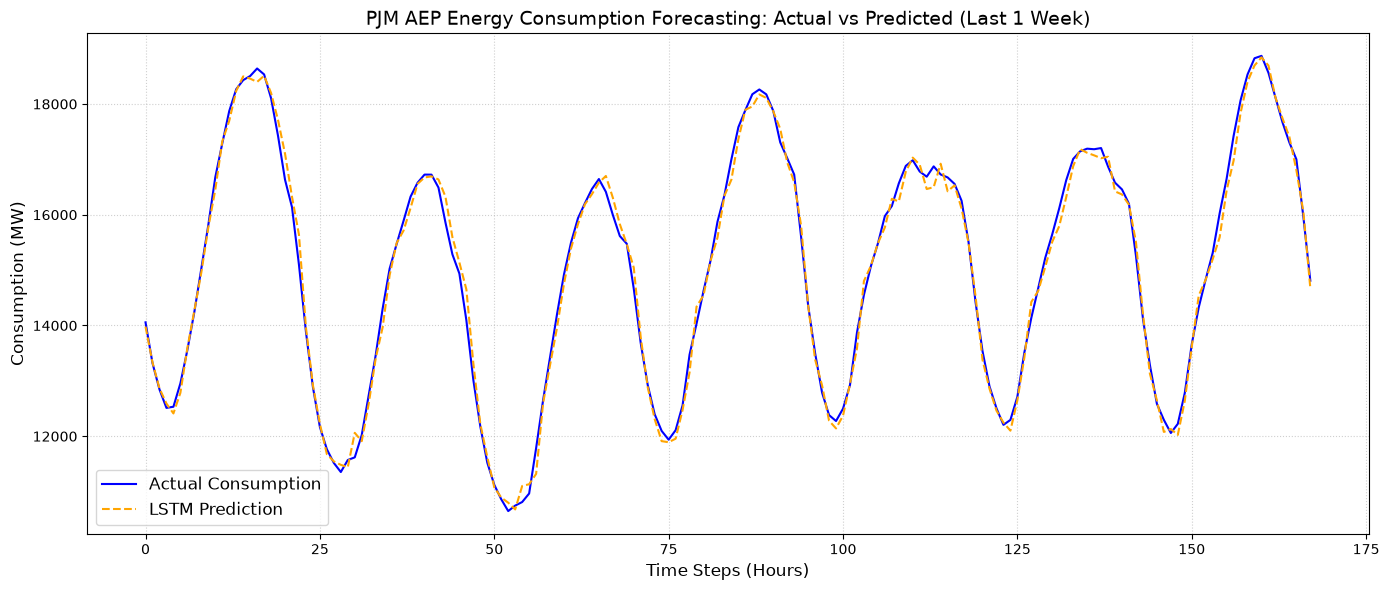

In [7]:
import matplotlib.pyplot as plt

# Plot a subset of test results (e.g., last 168 hours / 1 week)
plot_hours = 168

plt.figure(figsize=(14, 6))
plt.plot(actuals_inv[-plot_hours:], label='Actual Consumption', color='blue', linewidth=1.5)
plt.plot(predictions_inv[-plot_hours:], label='LSTM Prediction', color='orange', linestyle='--', linewidth=1.5)
plt.title('PJM AEP Energy Consumption Forecasting: Actual vs Predicted (Last 1 Week)', fontsize=14)
plt.xlabel('Time Steps (Hours)', fontsize=12)
plt.ylabel('Consumption (MW)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import r2_score

# Calculate R2 Score
r2 = r2_score(actuals_inv, predictions_inv)

# Calculate Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((actuals_inv - predictions_inv) / actuals_inv)) * 100

print(f"R2 Score: {r2:.4f}")
print(f"MAPE: {mape:.2f}%")

R2 Score: 0.9931
MAPE: 1.04%


In [9]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = np.asarray(actuals_inv).reshape(-1)
y_pred = np.asarray(predictions_inv).reshape(-1)

y_baseline = y_true[:-24]
y_eval = y_true[24:]
y_pred_eval = y_pred[24:]

baseline_mae = mean_absolute_error(y_eval, y_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_eval, y_baseline))

lstm_mae = mean_absolute_error(y_eval, y_pred_eval)
lstm_rmse = np.sqrt(mean_squared_error(y_eval, y_pred_eval))

improvement_mae = ((baseline_mae - lstm_mae) / baseline_mae) * 100

print(f"Fair Baseline (24h Lag) MAE: {baseline_mae:.2f} MW")
print(f"Fair Baseline (24h Lag) RMSE: {baseline_rmse:.2f} MW")
print(f"LSTM MAE on aligned eval set: {lstm_mae:.2f} MW")
print(f"LSTM RMSE on aligned eval set: {lstm_rmse:.2f} MW") # اضافه شده
print(f"True LSTM Improvement over Fair Baseline: {improvement_mae:.2f}%")

Fair Baseline (24h Lag) MAE: 925.95 MW
Fair Baseline (24h Lag) RMSE: 1221.46 MW
LSTM MAE on aligned eval set: 154.39 MW
LSTM RMSE on aligned eval set: 206.02 MW
True LSTM Improvement over Fair Baseline: 83.33%


In [10]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

seq_length = 24
test_timestamps = test_df.index[seq_length:]

assert len(test_timestamps) == len(actuals_inv) == len(predictions_inv), (
    "Timestamps, actual values, and predictions must have equal lengths."
)

test_results_df = pd.DataFrame({
    'timestamp': test_timestamps,
    'actual': actuals_inv.reshape(-1),
    'predicted': predictions_inv.reshape(-1)
})

df_indexed = df.copy()
df_indexed.index = pd.to_datetime(df_indexed.index)

assert not df_indexed.index.duplicated().any(), (
    "Duplicate timestamps found in the original DataFrame."
)

baseline_actuals = []
eval_actuals = []
eval_predictions = []

for _, row in test_results_df.iterrows():
    target_time = row['timestamp'] - pd.Timedelta(hours=24)
    if target_time in df_indexed.index:
        baseline_val = df_indexed.loc[target_time, 'consumption_mw']
        baseline_actuals.append(baseline_val)
        eval_actuals.append(row['actual'])
        eval_predictions.append(row['predicted'])

baseline_actuals = np.array(baseline_actuals)
eval_actuals = np.array(eval_actuals)
eval_predictions = np.array(eval_predictions)

print(f"Total test predictions: {len(test_results_df)}")
print(f"Skipped samples: {len(test_results_df) - len(eval_actuals)}")

assert len(eval_actuals) > 0, "No aligned evaluation samples found."

base_mae = mean_absolute_error(eval_actuals, baseline_actuals)
base_rmse = np.sqrt(mean_squared_error(eval_actuals, baseline_actuals))

lstm_mae = mean_absolute_error(eval_actuals, eval_predictions)
lstm_rmse = np.sqrt(mean_squared_error(eval_actuals, eval_predictions))

if base_mae > 0:
    improvement = ((base_mae - lstm_mae) / base_mae) * 100
else:
    improvement = 0.0

print(f"Evaluated samples count: {len(eval_actuals)}")
print(f"Time-Aligned Baseline MAE: {base_mae:.2f} MW")
print(f"Time-Aligned Baseline RMSE: {base_rmse:.2f} MW")
print(f"LSTM MAE: {lstm_mae:.2f} MW")
print(f"LSTM RMSE: {lstm_rmse:.2f} MW")
print(f"True Verified Improvement: {improvement:.2f}%")

Total test predictions: 18167
Skipped samples: 2
Evaluated samples count: 18165
Time-Aligned Baseline MAE: 925.27 MW
Time-Aligned Baseline RMSE: 1220.81 MW
LSTM MAE: 154.41 MW
LSTM RMSE: 206.01 MW
True Verified Improvement: 83.31%


In [11]:
import os
import torch
import joblib

os.makedirs("../models", exist_ok=True)
torch.save(model.state_dict(), "../models/energy_lstm_model.pth")
joblib.dump(scaler, "../models/scaler.pkl")
print("Model and scaler saved successfully to root models directory!")

Model and scaler saved successfully to root models directory!


In [20]:
import torch
import joblib
import numpy as np

# 1. Test loading scaler
loaded_scaler = joblib.load("../models/scaler.pkl")
print("Scaler loaded successfully!")

# 2. Test loading model weights with exact training architecture (num_layers=1, hidden_size=50)
test_model = EnergyLSTM(
    input_size=1, 
    hidden_size=50, 
    num_layers=1, 
    output_dim=1
)

test_model.load_state_dict(torch.load("../models/energy_lstm_model.pth", map_location=torch.device('cpu')))
test_model.eval()
print("Model weights loaded successfully and set to eval mode!")

# 3. Quick inference test with a dummy 24-hour sequence
dummy_seq = np.random.rand(24, 1)
scaled_dummy = loaded_scaler.transform(dummy_seq)
tensor_dummy = torch.tensor(scaled_dummy, dtype=torch.float32).unsqueeze(0)

with torch.no_grad():
    pred = test_model(tensor_dummy)
    
unscaled_pred = loaded_scaler.inverse_transform(pred.numpy())
print(f"Test prediction output (MW): {unscaled_pred[0][0]:.2f}")

Scaler loaded successfully!
Model weights loaded successfully and set to eval mode!


/mnt/d809bc61-ebac-4ca7-8e1e-e0a6d7e8f201/Documents/Programming/MyProjects/energy-forecasting-mlops/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


Test prediction output (MW): 6649.18
